# Geometry + Colorimetry Fusion: Pre / Per / Post-Exercise Classification

This notebook combines the two approaches previously tested:
- **Colorimetry** (`colorimetry` notebook): 3 best (non-scene) features (selected based on Random Forest feature importance).
- **Facial Geometry** (`geometric-features` notebook): 3 best features (selected based on Random Forest feature importance).



## 1 - Library

In [1]:
import urllib.request
from pathlib import Path

import cv2
import mediapipe as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             classification_report, ConfusionMatrixDisplay)

# ---------- Parameters ----------
FOLDER_FEATURES_SELECTION = Path("data/dataset_squat")   # Adapt if needed
FOLDER_TEMPORAL_ANALYSIS = Path("data/dataset_squat_temporal_analysis")   # Adapt if needed
GROUPES = ["pre", "per", "post"]
SEED = 42
ROI_RATIO = 0.6            # Central face region used for colorimetry
Path("src/figures").mkdir(exist_ok=True)

# ---------- Feature schema (scene/background-dependent color features excluded) ----------
COLOR_FEATURES = [
    "moyenne_srgb_B", "moyenne_srgb_G", "moyenne_srgb_R",
    "moyenne_lin_B", "moyenne_lin_G", "moyenne_lin_R",
    "luma_srgb_moy", "luminance_lin_moy", "luma_min", "luma_max",
    "luma_p1", "luma_p99", "etendue_p1_p99", "plage_dynamique_stops",
    "contraste_rms", "contraste_michelson", "pct_sature", "pct_sous_expose",
    "face_rg", "face_bg", "face_y", "face_cct",
]
GEOMETRY_FEATURES = [
    "eye_left_opening_ratio", "eye_right_opening_ratio", "eye_opening_asymmetry",
    "eye_left_width", "eye_left_height", "eye_right_width", "eye_right_height",
    "eye_left_area", "eye_right_area", "mouth_opening_ratio", "mouth_width",
    "mouth_height", "mouth_outer_area", "mouth_inner_area", "mouth_corner_angle_deg",
    "eye_left_edge_density", "eye_right_edge_density", "eye_edge_density_asymmetry",
    "mouth_edge_density", "face_edge_density", "left_right_edge_asymmetry",
]
FEATURES = COLOR_FEATURES + GEOMETRY_FEATURES
SOURCE = {**{f: "colorimetry" for f in COLOR_FEATURES},
          **{f: "geometry" for f in GEOMETRY_FEATURES}}
TOP_COLOR = COLOR_FEATURES
TOP_FUSION = FEATURES

## 2 - Features Function

### 2.1 Face Detection (Viola-Jones)

In [2]:
_CASCADE = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")
if _CASCADE.empty():
    raise RuntimeError("Cascade not loaded: check your OpenCV installation")


def detect_face(img, scale_factor=1.1, min_neighbors=5, min_size=(60, 60)):
    """Input: BGR image. Output: bbox (x, y, w, h) of the largest face, or None."""
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    visages = _CASCADE.detectMultiScale(gris, scaleFactor=scale_factor,
                                        minNeighbors=min_neighbors, minSize=min_size)
    if len(visages) == 0:
        return None
    x, y, w, h = max(visages, key=lambda b: b[2] * b[3])
    return int(x), int(y), int(w), int(h)


def reframe(img, bbox, roi_ratio=1.0):
    """Crop the bounding box (roi_ratio=1.0: full face; 0.6: face center)."""
    x, y, w, h = bbox
    dx, dy = int(w * (1 - roi_ratio) / 2), int(h * (1 - roi_ratio) / 2)
    return img[y + dy : y + h - dy, x + dx : x + w - dx]

### 2.2 Colorimetric features

In [3]:
CANAUX = ("B", "G", "R")   # OpenCV channel order

_niveaux = np.arange(256, dtype=np.float32) / 255.0
_LUT_LIN_U8 = np.where(_niveaux <= 0.04045, _niveaux / 12.92,
                       ((_niveaux + 0.055) / 1.055) ** 2.4).astype(np.float32)

# Ligne Y et somme des lignes X, Y, Z de la matrice sRGB -> XYZ (seul y est nÃƒÂ©cessaire)
_Y_ROW = np.array([0.2126729, 0.7151522, 0.0721750])
_SUM_ROW = np.array([0.4124564 + 0.2126729 + 0.0193339,
                     0.3575761 + 0.7151522 + 0.1191920,
                     0.1804375 + 0.0721750 + 0.9503041])


def _valeur_max(img):
    return float(np.iinfo(img.dtype).max) if np.issubdtype(img.dtype, np.integer) else 1.0


def normaliser(img):
    """BGR image -> float32 in [0, 1] (sRGB values)."""
    return img.astype(np.float32) * np.float32(1.0 / _valeur_max(img))


def srgb_vers_lineaire(img_bgr):
    """BGR image -> linear light float32 in [0, 1]."""
    if img_bgr.dtype == np.uint8:
        return cv2.LUT(img_bgr, _LUT_LIN_U8)
    c = normaliser(img_bgr)
    return np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4).astype(np.float32)


def colorimetry(img, bbox, roi_ratio=ROI_RATIO):
    """Input: BGR image + face bounding box. Output: face-center color features."""
    roi = reframe(img, bbox, roi_ratio)
    v_srgb = normaliser(roi)

    v_lin = srgb_vers_lineaire(roi)
    luma = 0.0722 * v_srgb[..., 0] + 0.7152 * v_srgb[..., 1] + 0.2126 * v_srgb[..., 2]
    lum_lin = 0.0722 * v_lin[..., 0] + 0.7152 * v_lin[..., 1] + 0.2126 * v_lin[..., 2]
    luma_flat, lum_lin_flat = luma.ravel(), lum_lin.ravel()
    luma_p1, luma_p99 = np.percentile(luma_flat, [1, 99])
    lum_p1, lum_p99 = np.percentile(lum_lin_flat, [1, 99])
    rgb_lin = v_lin.reshape(-1, 3).mean(axis=0, dtype=np.float64)[::-1]
    xyz_sum = float(_SUM_ROW @ rgb_lin)
    face_x = float((0.4124564 * rgb_lin[0] + 0.3575761 * rgb_lin[1] + 0.1804375 * rgb_lin[2]) / (xyz_sum + 1e-12))
    face_y = float((_Y_ROW @ rgb_lin) / (xyz_sum + 1e-12))
    n = (face_x - 0.3320) / (0.1858 - face_y + 1e-12)
    face_cct = float(np.clip(449 * n**3 + 3525 * n**2 + 6823.3 * n + 5520.33, 1500, 15000))
    return {
        "moyenne_srgb_B": float(v_srgb[..., 0].mean(dtype=np.float64)),
        "moyenne_srgb_G": float(v_srgb[..., 1].mean(dtype=np.float64)),
        "moyenne_srgb_R": float(v_srgb[..., 2].mean(dtype=np.float64)),
        "moyenne_lin_B": float(v_lin[..., 0].mean(dtype=np.float64)),
        "moyenne_lin_G": float(v_lin[..., 1].mean(dtype=np.float64)),
        "moyenne_lin_R": float(v_lin[..., 2].mean(dtype=np.float64)),
        "luma_srgb_moy": float(luma.mean(dtype=np.float64)),
        "luminance_lin_moy": float(lum_lin.mean(dtype=np.float64)),
        "luma_min": float(luma.min()), "luma_max": float(luma.max()),
        "luma_p1": float(luma_p1), "luma_p99": float(luma_p99),
        "etendue_p1_p99": float(luma_p99 - luma_p1),
        "plage_dynamique_stops": float(np.log2((lum_p99 + 1e-4) / (lum_p1 + 1e-4))),
        "contraste_rms": float(luma.std(dtype=np.float64)),
        "contraste_michelson": float((luma_p99 - luma_p1) / (luma_p99 + luma_p1 + 1e-9)),
        "pct_sature": float(100 * np.mean(luma >= 0.98)),
        "pct_sous_expose": float(100 * np.mean(luma <= 0.02)),
        "face_rg": float(rgb_lin[0] / max(rgb_lin[1], 1e-6)),
        "face_bg": float(rgb_lin[2] / max(rgb_lin[1], 1e-6)),
        "face_y": face_y, "face_cct": face_cct,
    }

### 2.3 Geometric features (MediaPipe FaceLandmarker + contours)

In [4]:
def remove_background(visage, iterations=1):
    """Replaces the background of the face crop with its median color (GrabCut)."""
    h, w = visage.shape[:2]
    masque = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)
    bord = max(2, int(min(h, w) * 0.04))
    masque[bord:-bord, bord:-bord] = cv2.GC_PR_FGD
    cv2.ellipse(masque, (w // 2, h // 2), (int(w * 0.42), int(h * 0.48)), 0, 0, 360, cv2.GC_FGD, -1)
    cv2.grabCut(visage, masque, None, np.zeros((1, 65)), np.zeros((1, 65)),
                iterations, cv2.GC_INIT_WITH_MASK)
    avant = np.isin(masque, (cv2.GC_FGD, cv2.GC_PR_FGD)).astype(np.uint8)
    noyau = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    avant = cv2.morphologyEx(cv2.morphologyEx(avant, cv2.MORPH_CLOSE, noyau), cv2.MORPH_OPEN, noyau)
    pixels_bord = np.concatenate((visage[:bord].reshape(-1, 3), visage[-bord:].reshape(-1, 3)))
    propre = np.broadcast_to(np.median(pixels_bord, axis=0).astype(np.uint8), visage.shape).copy()
    propre[avant > 0] = visage[avant > 0]
    return propre


_MODELE_LANDMARKS = Path("src/models/face_landmarker.task")
_URL_LANDMARKS = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
                  "face_landmarker/float16/1/face_landmarker.task")
if not _MODELE_LANDMARKS.exists():
    _MODELE_LANDMARKS.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(_URL_LANDMARKS, _MODELE_LANDMARKS)
_LANDMARKER = mp.tasks.vision.FaceLandmarker.create_from_options(
    mp.tasks.vision.FaceLandmarkerOptions(
        base_options=mp.tasks.BaseOptions(model_asset_path=str(_MODELE_LANDMARKS)),
        running_mode=mp.tasks.vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=0.5, min_face_presence_confidence=0.5))

_GROUPES_LANDMARKS = {
    "oeil_g": [33, 160, 158, 133, 153, 144],
    "oeil_d": [362, 385, 387, 263, 373, 380],
    "bouche_ext": [61, 146, 91, 181, 84, 17, 314, 405, 321, 375, 291, 409, 270, 269, 267, 0, 37, 39, 40],
    "bouche_int": [78, 95, 88, 178, 87, 14, 317, 402, 318, 324, 308, 415, 310, 311, 312, 13, 82, 81],
}


def _points_landmarks(visage):
    rgb = cv2.cvtColor(visage, cv2.COLOR_BGR2RGB)
    res = _LANDMARKER.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
    if not res.face_landmarks:
        return None
    h, w = visage.shape[:2]
    pts = np.array([(l.x * w, l.y * h) for l in res.face_landmarks[0]], dtype=np.float32)
    return pts if np.isfinite(pts).all() else None


def _dist(p, a, b):
    return float(np.linalg.norm(p[a] - p[b]))


def _aire(poly):
    return float(abs(cv2.contourArea(poly.astype(np.float32))))


def _roi_rel(gris, x0, y0, x1, y1):
    h, w = gris.shape[:2]
    return gris[int(h * y0):int(h * y1), int(w * x0):int(w * x1)]


def geometrie(visage):
    """Input: BGR face crop (background removed).
    Output: (dictionary of geometric features, landmarks_ok)."""
    h, w = visage.shape[:2]
    gris = cv2.cvtColor(visage, cv2.COLOR_BGR2GRAY)
    pts = _points_landmarks(visage)
    feats = {}

    if pts is not None:
        inter = max(_dist(pts, 33, 263), 1.0)                       # Interocular distance (normalization)
        lw, rw = _dist(pts, 33, 133) / inter, _dist(pts, 362, 263) / inter
        lh = np.mean([_dist(pts, 160, 144), _dist(pts, 158, 153)]) / inter
        rh = np.mean([_dist(pts, 385, 380), _dist(pts, 387, 373)]) / inter
        bw, bh = _dist(pts, 61, 291) / inter, _dist(pts, 13, 14) / inter
        g = {k: pts[np.asarray(v, dtype=int)] for k, v in _GROUPES_LANDMARKS.items()}
        feats.update({
            "eye_left_opening_ratio": float(lh / max(lw, 1e-6)),
            "eye_right_opening_ratio": float(rh / max(rw, 1e-6)),
            "eye_opening_asymmetry": float(abs(lh - rh)),
            "eye_left_width": float(lw), "eye_left_height": float(lh),
            "eye_right_width": float(rw), "eye_right_height": float(rh),
            "eye_left_area": _aire(g["oeil_g"]) / inter ** 2,
            "eye_right_area": _aire(g["oeil_d"]) / inter ** 2,
            "mouth_opening_ratio": float(bh / max(bw, 1e-6)),
            "mouth_width": float(bw), "mouth_height": float(bh),
            "mouth_outer_area": _aire(g["bouche_ext"]) / inter ** 2,
            "mouth_inner_area": _aire(g["bouche_int"]) / inter ** 2,
            "mouth_corner_angle_deg": float(np.degrees(np.arctan2(
                pts[13, 1] - (pts[61, 1] + pts[291, 1]) / 2, max(_dist(pts, 61, 291), 1.0)))),
        })

    # Edge density (Canny): same regions as in the geometry notebook
    canny = lambda r: float(np.mean(cv2.Canny(r, 30, 100) > 0))
    bords = cv2.Canny(gris, 30, 100)
    moitie = w // 2
    gauche = bords[:, :moitie].astype(float)
    droite = np.fliplr(bords[:, w - moitie:].astype(float))
    d_og = canny(_roi_rel(gris, 0.08, 0.22, 0.52, 0.62))
    d_od = canny(_roi_rel(gris, 0.48, 0.22, 0.92, 0.62))
    feats.update({
        "eye_left_edge_density": d_og, "eye_right_edge_density": d_od,
        "eye_edge_density_asymmetry": abs(d_og - d_od),
        "mouth_edge_density": canny(_roi_rel(gris, 0.16, 0.48, 0.84, 0.96)),
        "face_edge_density": float(np.mean(bords > 0)),
        "left_right_edge_asymmetry": float(np.mean(np.abs(gauche - droite)) / 255.0),
    })
    return feats, pts is not None

### 2.4 Fusion function : image Ã¢â€ â€™ colorimetric + geometric features

In [5]:
def extract_features(chemin):
    """Input: image path. Output: dict {color + geometry features}, or None if extraction fails
    (unreadable image, no Viola-Jones face detected, or missing MediaPipe landmarks)."""
    img = cv2.imread(str(chemin))
    if img is None:
        raise FileNotFoundError(f"Unable to read image: {chemin}")
    bbox = detect_face(img)                       # Single detection, shared by both methods
    if bbox is None:
        return None

    feats_c = colorimetry(img, bbox, roi_ratio=ROI_RATIO)               # Face center (60%)
    visage_complet = remove_background(reframe(img, bbox, roi_ratio=1.0))   # Full face, background neutralized
    feats_g, landmarks_ok = geometrie(visage_complet)
    if not landmarks_ok:
        return None
    return {**feats_c, **feats_g}

### 2.5 Train / Validation / Test Split and Feature Extraction on the Entire Dataset

In [6]:
# Dataset inventory + stratified random split 60 / 20 / 20 (same as in the two original notebooks)
fichiers = pd.DataFrame([
    {"chemin": str(c), "groupe": g}
    for g in GROUPES for c in sorted((FOLDER_FEATURES_SELECTION / f"squat_{g}").glob("*.jpg"))
])
trainval, test = train_test_split(fichiers, test_size=0.20, stratify=fichiers["groupe"], random_state=SEED)
train, val = train_test_split(trainval, test_size=0.25, stratify=trainval["groupe"], random_state=SEED)

assert not (set(train["chemin"]) & set(val["chemin"]))
assert not (set(train["chemin"]) & set(test["chemin"]))
assert not (set(val["chemin"]) & set(test["chemin"]))
splits = pd.concat([train.assign(jeu="train"), val.assign(jeu="val"), test.assign(jeu="test")])

# Feature extraction (computed only once, then reused from the CSV)
lignes, ecartees = [], 0
for ligne in splits.itertuples(index=False):
    feats = extract_features(ligne.chemin)
    if feats is None:
        ecartees += 1
        continue
    lignes.append({"chemin": ligne.chemin, "groupe": ligne.groupe, "jeu": ligne.jeu, **feats})

data = pd.DataFrame(lignes)
data.to_csv("features_fusion.csv", index=False)

print(f"{len(data)} usable images, {ecartees} discarded (no face or no landmarks)")
print(pd.crosstab(data["jeu"], data["groupe"]).loc[["train", "val", "test"], GROUPES])

1457 usable images, 43 discarded (no face or no landmarks)
groupe  pre  per  post
jeu                   
train   289  292   288
val      98   99    99
test     96   98    98


### 2.6 Visual example: Viola-Jones ROI, central color ROI, and background removal

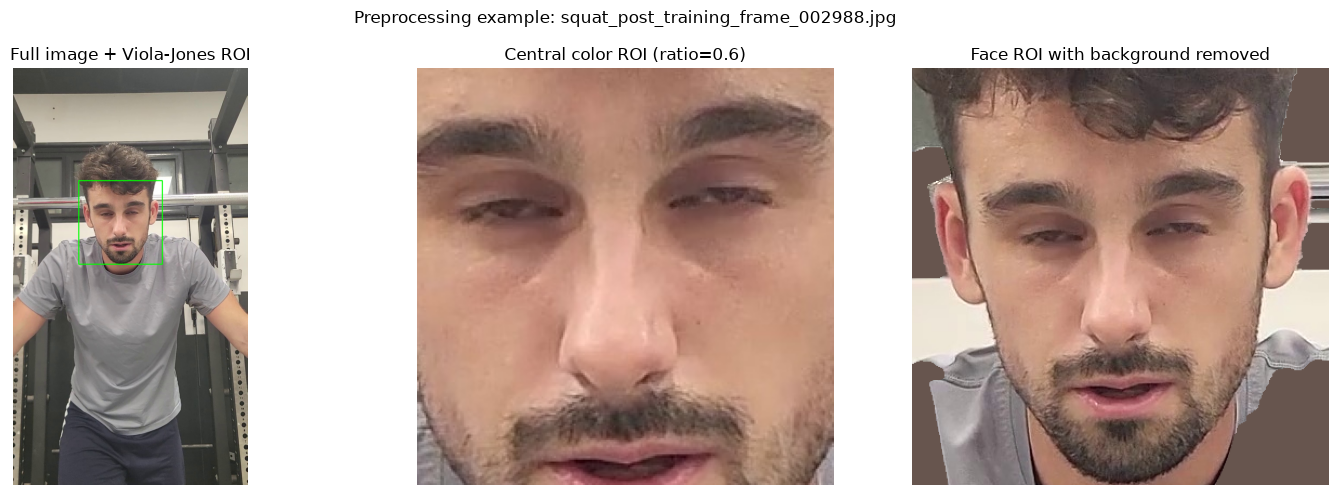

In [11]:
# One reproducible usable test image for the preprocessing visualisation.
_example_path = None
_example_img = None
_example_bbox = None
for _path in np.random.default_rng(SEED).permutation(test["chemin"].to_numpy()):
    _img = cv2.imread(str(_path))
    if _img is None:
        continue
    _bbox = detect_face(_img)
    if _bbox is not None:
        _example_path, _example_img, _example_bbox = _path, _img, _bbox
        break
if _example_img is None:
    raise RuntimeError("No test image with a detected face was found for visualisation")
_example_face = reframe(_example_img, _example_bbox, roi_ratio=1.0)
_example_face_without_background = remove_background(_example_face)
_example_color_roi = reframe(_example_img, _example_bbox, roi_ratio=ROI_RATIO)
_example_full_view = _example_img.copy()
_ex, _ey, _ew, _eh = _example_bbox
cv2.rectangle(_example_full_view, (_ex, _ey), (_ex + _ew, _ey + _eh), (0, 255, 0), 3)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(cv2.cvtColor(_example_full_view, cv2.COLOR_BGR2RGB))
axes[0].set_title("Full image + Viola-Jones ROI")
axes[1].imshow(cv2.cvtColor(_example_color_roi, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Central color ROI (ratio={ROI_RATIO})")
axes[2].imshow(cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2RGB))
axes[2].set_title("Face ROI with background removed")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Preprocessing example: {Path(_example_path).name}")
plt.tight_layout()
plt.show()

### 2.7 Visual example: geometric feature measurements

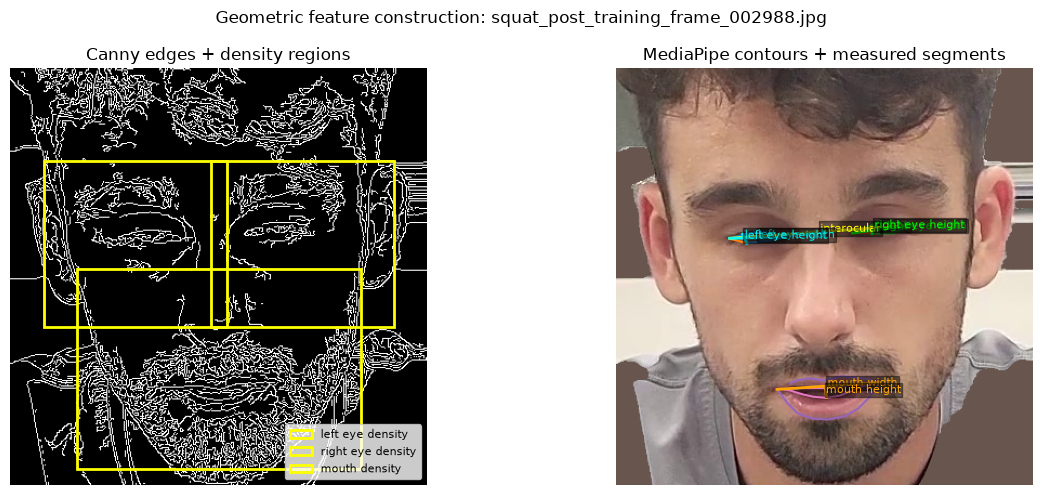

In [14]:
# The same test example, with the exact edge-density regions and landmark segments.
_example_gray = cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2GRAY)
_example_edges = cv2.Canny(_example_gray, 30, 100)
_example_h, _example_w = _example_gray.shape
_edge_regions = {
    "left eye density": (0.08, 0.22, 0.52, 0.62, "#00E5FF"),
    "right eye density": (0.48, 0.22, 0.92, 0.62, "#FF4DFF"),
    "mouth density": (0.16, 0.48, 0.84, 0.96, "#FFD000"),
}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].imshow(_example_edges, cmap="gray")
for _label, (_x0, _y0, _x1, _y1, _color) in _edge_regions.items():
    _rect = plt.Rectangle((_x0 * _example_w, _y0 * _example_h),
                          (_x1 - _x0) * _example_w, (_y1 - _y0) * _example_h,
                          fill=False, linewidth=2, label=_label, color=_color)
    axes[0].add_patch(_rect)
axes[0].set_title("Canny edges + density regions")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(_example_face_without_background, cv2.COLOR_BGR2RGB))
_example_points = _points_landmarks(_example_face_without_background)
if _example_points is None:
    raise RuntimeError("MediaPipe landmarks unavailable for geometric visualisation")
_contour_handles = []
for _name, _indices in _GROUPES_LANDMARKS.items():
    _polygon = np.rint(_example_points[np.asarray(_indices, dtype=int)]).astype(np.int32).reshape(-1, 1, 2)
    _contour_handles.append(axes[1].plot(_polygon[:, 0, 0], _polygon[:, 0, 1], linewidth=1.5, label=_name)[0])
    axes[1].plot([_polygon[-1, 0, 0], _polygon[0, 0, 0]],
                 [_polygon[-1, 0, 1], _polygon[0, 0, 1]], linewidth=1.5)
_measurements = {
    "interocular": (33, 263, "yellow"),
    "left eye width": (33, 133, "cyan"),
    "left eye height": (160, 144, "cyan"),
    "right eye width": (362, 263, "lime"),
    "right eye height": (385, 380, "lime"),
    "mouth width": (61, 291, "orange"),
    "mouth height": (13, 14, "orange"),
}
_measurement_handles = []
for _label, (_a, _b, _color) in _measurements.items():
    _pa, _pb = _example_points[_a], _example_points[_b]
    _measurement_handles.append(axes[1].plot([_pa[0], _pb[0]], [_pa[1], _pb[1]],
        color=_color, linewidth=2, label=_label)[0])
axes[1].set_title("MediaPipe contours + measured segments")
axes[1].legend(handles=_contour_handles + _measurement_handles,
               bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8, framealpha=0.85)
axes[1].axis("off")
fig.suptitle(f"Geometric feature construction: {Path(_example_path).name}")
fig.subplots_adjust(right=0.76)
plt.tight_layout()
plt.show()

## 3 - Model

In [7]:
# Compare both complete pipelines, then rank every fusion feature with one RF.
JEUX_FEATURES = {
    "Colorimetry (all face ROI)": COLOR_FEATURES,
    "Geometry (all)": GEOMETRY_FEATURES,
    "Fusion (all features)": FEATURES
}

manquantes = [f for f in FEATURES if f not in data.columns]
assert not manquantes, f"Missing features in the dataset: {manquantes}"



def create_models():
    """Create new models at each call (no shared state between feature sets)."""
    return {
        "Baseline (majority class)": DummyClassifier(strategy="most_frequent"),
        "Logistic Regression": make_pipeline(
            StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
        "Random Forest": RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }

FINAL_MODEL = "Random Forest"   # Selected interpretable model for the fusion

## 4 - Training and Test

jeu_features,Colorimetry (all face ROI),Fusion (all features),Geometry (all)
modele,,,
Baseline (majority class),0.333,0.333,0.333
Logistic Regression,0.892,0.959,0.926
Random Forest,0.970,0.990,0.953


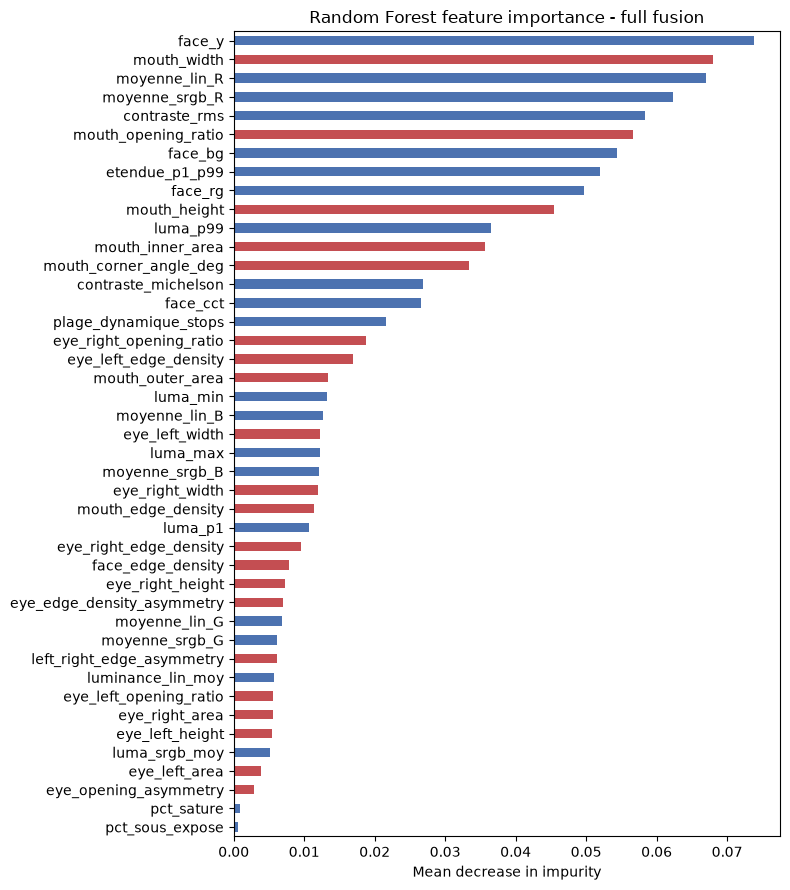

Full-feature fusion model (test set)
Accuracy: 0.979
Balanced accuracy: 0.979


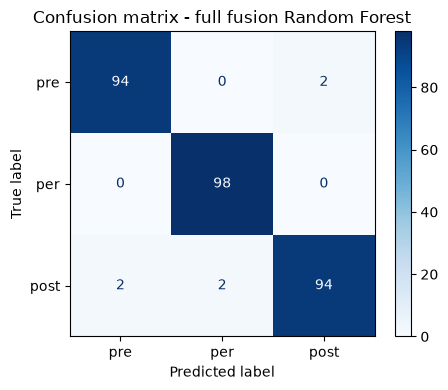

,n_features,features,accuracy_test,balanced_accuracy_test
0,10,"face_y, mouth_width, moyenne_lin_R, moyenne_sr...",0.969178,0.969175
1,5,"face_y, mouth_width, moyenne_lin_R, moyenne_sr...",0.914384,0.914753
2,3,"face_y, mouth_width, moyenne_lin_R",0.907534,0.907738
3,2,"face_y, mouth_width",0.839041,0.839427
4,1,face_y,0.695205,0.695224


In [10]:
d_train, d_val, d_test = (data[data["jeu"] == j] for j in ("train", "val", "test"))
y_train, y_val, y_test = d_train["groupe"], d_val["groupe"], d_test["groupe"]

# Keep the separated colorimetry/geometry comparison, using every eligible feature.
lignes = []
for nom_jeu, feats in JEUX_FEATURES.items():
    for nom_modele, modele in create_models().items():
        modele.fit(d_train[feats], y_train)
        pred = modele.predict(d_val[feats])
        lignes.append({"jeu_features": nom_jeu, "modele": nom_modele,
                       "accuracy_val": accuracy_score(y_val, pred),
                       "balanced_acc_val": balanced_accuracy_score(y_val, pred)})
scores_val = pd.DataFrame(lignes)
display(scores_val.pivot(index="modele", columns="jeu_features", values="balanced_acc_val").round(3))

# Rank all fusion features on train only, then evaluate fixed top-k subsets on test.
X_trainval = pd.concat([d_train, d_val])
y_trainval = pd.concat([y_train, y_val])
full_model = create_models()[FINAL_MODEL]
full_model.fit(X_trainval[FEATURES], y_trainval)
fusion_ranker = full_model
importance = pd.Series(full_model.feature_importances_, index=FEATURES).sort_values(ascending=False)

# Diagnostics for the complete fusion model, before feature reduction.
importance_plot = importance.sort_values()
importance_colors = ["#4C72B0" if SOURCE[f] == "colorimetry" else "#C44E52" for f in importance_plot.index]
fig, ax = plt.subplots(figsize=(8, 9))
importance_plot.plot.barh(ax=ax, color=importance_colors)
ax.set_title("Random Forest feature importance - full fusion")
ax.set_xlabel("Mean decrease in impurity")
plt.tight_layout()
plt.savefig("src/figures/rf_feature_importance_fusion_full.png", dpi=150, bbox_inches="tight")
plt.show()

full_pred = full_model.predict(d_test[FEATURES])
print("Full-feature fusion model (test set)")
print(f"Accuracy: {accuracy_score(y_test, full_pred):.3f}")
print(f"Balanced accuracy: {balanced_accuracy_score(y_test, full_pred):.3f}")
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, full_pred, labels=GROUPES, cmap="Blues", ax=ax)
ax.set_title("Confusion matrix - full fusion Random Forest")
plt.tight_layout()
plt.savefig("src/figures/confusion_rf_fusion_full.png", dpi=150, bbox_inches="tight")
plt.show()

TOP_K = [10, 5, 3, 2, 1]
top_features = {k: importance.head(k).index.tolist() for k in TOP_K}
selection_results, selected_models = [], {}
for k in TOP_K:
    feats = top_features[k]
    model = create_models()[FINAL_MODEL]
    model.fit(X_trainval[feats], y_trainval)
    selected_models[k] = model
    pred = model.predict(d_test[feats])
    selection_results.append({"n_features": k, "features": ", ".join(feats),
                              "accuracy_test": accuracy_score(y_test, pred),
                              "balanced_accuracy_test": balanced_accuracy_score(y_test, pred)})
selection_results = pd.DataFrame(selection_results)
display(selection_results)
final_models = {}
for nom_jeu, feats in JEUX_FEATURES.items():
    model = create_models()[FINAL_MODEL]
    model.fit(X_trainval[feats], y_trainval)
    final_models[nom_jeu] = model
final_models["Fusion (all features)"] = full_model